# Laboratorium 5 - Reprezentacje tekstu: BPE i Word2Vec

## 1. Instalacja i import

In [1]:
!pip -q install tokenizers gensim scikit-learn matplotlib numpy

In [2]:
import re
from itertools import combinations, product

import numpy as np
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

np.random.seed(0)

## 2. Korpus

In [3]:
WYRAZ = 'pilot'

LOTNICTWO = [
    'Pilot sprawdził przyrządy w kabinie przed startem samolotu.',
    'Pilot poprowadził samolot nad chmurami na dużej wysokości.',
    'Doświadczony pilot wylądował na lotnisku mimo silnego wiatru.',
    'Pilot poinformował pasażerów o turbulencjach nad morzem.',
    'Po starcie pilot utrzymywał samolot na stałej wysokości.',
    'Pilot rozmawiał z wieżą kontrolną przez radio w kabinie.',
    'Na lotnisku pilot czekał na zgodę na start.',
    'Pilot przywitał pasażerów na pokładzie samolotu.',
    'Pilot obniżył samolot nad pasem startowym.',
    'Pilot uspokoił pasażerów podczas silnych turbulencji.',
    'Pilot widział lotnisko z dużej wysokości.',
    'Pilot zostawił samolot na lotnisku po długim locie.',
    'W kabinie pilot zapiął pasy przed lądowaniem.',
    'Młody pilot odbył pierwszy samodzielny lot.',
    'Pilot skierował samolot na zapasowe lotnisko.',
    'Kapitan i drugi pilot przygotowali plan lotu.',
    'Pilot wylądował bezpiecznie na mokrym pasie startowym.',
    'Każdy pilot przechodzi regularne badania i szkolenia.',
    'Pilot wrócił do kabiny po rozmowie z załogą.',
    'Pilot zwiększył wysokość, żeby ominąć chmury burzowe.',
]

TELEWIZOR = [
    'Pilot do telewizora leżał na kanapie.',
    'Wziąłem pilot i przełączyłem kanał na wiadomości.',
    'Pilot przestał działać, bo wyczerpały się baterie.',
    'Babcia nacisnęła przycisk i pilot włączył telewizor.',
    'Pilot włącza telewizor i zmienia kanał.',
    'Brat schował pilot pod poduszkę na kanapie.',
    'Wymieniłem baterie, więc pilot znowu działa.',
    'Nowy pilot ma jeden przycisk do nagrywania.',
    'Tata zawsze trzyma pilot w ręce podczas meczu.',
    'Uniwersalny pilot obsługuje telewizor i odtwarzacz.',
    'Na stole leżał pilot obok gazety z programem.',
    'Gdy pilot zginął, przełączaliśmy kanał ręcznie.',
    'Pilot spadł z kanapy i wypadły z niego baterie.',
    'Siostra ukryła pilot, żeby obejrzeć swój serial.',
    'Pilot ma wyraźne cyfry, więc łatwo wybrać kanał.',
    'Po awarii prądu pilot nie włączał telewizora.',
    'Pilot leżał między poduszkami na kanapie.',
    'Dziecko nacisnęło przycisk i pilot zmienił głośność.',
    'Mały pilot mieści się w kieszeni szlafroka.',
    'Stary pilot obsługuje tylko jeden telewizor.',
]

BEZ_WYRAZU = [
    'Samolot wystartował z lotniska o świcie.',
    'Pasażerowie czekali na lotnisku na opóźniony samolot.',
    'Stewardesa policzyła pasażerów w samolocie.',
    'Samolot leciał na dużej wysokości nad górami.',
    'Kontroler na wieży obserwował samolot na pasie startowym.',
    'Załoga sprawdziła w kabinie listę pasażerów.',
    'Na lotnisku stał samolot gotowy do startu.',
    'Telewizor stoi w salonie naprzeciwko kanapy.',
    'Wieczorem cała rodzina ogląda telewizor na kanapie.',
    'Ten kanał nadaje filmy przyrodnicze przez całą noc.',
    'Nowy telewizor ma cienki ekran i dobry dźwięk.',
    'Baterie w zegarze trzeba wymieniać co roku.',
    'Przycisk zasilania znajduje się z tyłu telewizora.',
    'Na kanapie siedział dziadek i wybierał kanał z filmami.',
    'Kupiłem baterie do latarki i nowy przycisk do dzwonka.',
    'Kot spał w słońcu na parapecie.',
    'W ogrodzie zakwitły pierwsze tulipany.',
    'Babcia upiekła szarlotkę na niedzielny obiad.',
    'Rano padał deszcz, a po południu wyszło słońce.',
    'Uczniowie napisali sprawdzian z matematyki.',
]

KORPUS = LOTNICTWO + TELEWIZOR + BEZ_WYRAZU

def slowa(zdanie):
    return re.sub(r'[^\w\s]', ' ', zdanie.lower()).split()


print('Pule: lotnictwo', len(LOTNICTWO), '| telewizor', len(TELEWIZOR),
      '| bez wyrazu', len(BEZ_WYRAZU), '| razem', len(KORPUS),
      '| różnych zdań', len(set(KORPUS)))
for nazwa, pula, ile in [('lotnictwo', LOTNICTWO, 1), ('telewizor', TELEWIZOR, 1),
                         ('bez wyrazu', BEZ_WYRAZU, 0)]:
    ok = all(slowa(z).count(WYRAZ) == ile for z in pula)
    print(f'{nazwa}: w każdym zdaniu "{WYRAZ}" występuje {ile} raz(y): {ok}')

Pule: lotnictwo 20 | telewizor 20 | bez wyrazu 20 | razem 60 | różnych zdań 60
lotnictwo: w każdym zdaniu "pilot" występuje 1 raz(y): True
telewizor: w każdym zdaniu "pilot" występuje 1 raz(y): True
bez wyrazu: w każdym zdaniu "pilot" występuje 0 raz(y): True


## 3. Próbka testowa do BPE

In [4]:
PARY = [
    ('samolot', 'samolotami'),
    ('telewizor', 'telewizorach'),
    ('lotnisku', 'lotniskami'),
    ('kabinie', 'kabinami'),
    ('kanał', 'kanałami'),
    ('baterie', 'bateriami'),
    ('przycisk', 'przyciskami'),
    ('wylądował', 'wylądowaliśmy'),
]
WIDZIANE = [p[0] for p in PARY]
NIEWIDZIANE = [p[1] for p in PARY]
SLOWA_KORPUSU = sorted({w for z in KORPUS for w in slowa(z)})

print(f'{"forma widziana":16s} {"w korpusie":>10s}   {"forma niewidziana":18s} {"w korpusie":>10s}')
for w, n in PARY:
    print(f'{w:16s} {str(w in SLOWA_KORPUSU):>10s}   {n:18s} {str(n in SLOWA_KORPUSU):>10s}')

forma widziana   w korpusie   forma niewidziana  w korpusie
samolot                True   samolotami              False
telewizor              True   telewizorach            False
lotnisku               True   lotniskami              False
kabinie                True   kabinami                False
kanał                  True   kanałami                False
baterie                True   bateriami               False
przycisk               True   przyciskami             False
wylądował              True   wylądowaliśmy           False


## 4. Hipoteza

Zwiększenie limitu słownika zmniejszy średnią liczbę tokenów w obu grupach form. Formy widziane w treningu przy największym słowniku powinny stać się pojedynczymi tokenami, a formy niewidziane nadal będą składane z kilku części, np. z tematu znanego z korpusu i osobnej końcówki, więc spadek będzie u nich mniejszy.

## 5. Tokenizacja BPE przy trzech limitach słownika

In [5]:
LIMITY = [100, 150, 2000]


def trenuj_bpe(limit):
    tok = Tokenizer(models.BPE(unk_token='[UNK]'))
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=limit, special_tokens=['[UNK]'], min_frequency=1)
    tok.train_from_iterator([z.lower() for z in KORPUS], trainer)
    return tok


tokenizery = {limit: trenuj_bpe(limit) for limit in LIMITY}


def podzial(limit, forma):
    return tokenizery[limit].encode(forma).tokens


print(f'{"limit":>6s} {"rozmiar":>8s} {"śr. tokenów":>12s} {"śr. tokenów":>12s} '
      f'{"[UNK]":>10s} {"[UNK]":>12s}')
print(f'{"":>6s} {"":>8s} {"widziane":>12s} {"niewidziane":>12s} '
      f'{"widziane":>10s} {"niewidziane":>12s}')
for limit in LIMITY:
    wynik = []
    for grupa in [WIDZIANE, NIEWIDZIANE]:
        tokeny = [podzial(limit, f) for f in grupa]
        wynik.append(np.mean([len(t) for t in tokeny]))
        wynik.append(sum('[UNK]' in t for t in tokeny))
    print(f'{limit:6d} {tokenizery[limit].get_vocab_size():8d} {wynik[0]:12.2f} {wynik[2]:12.2f} '
          f'{wynik[1]:10d} {wynik[3]:12d}')

 limit  rozmiar  śr. tokenów  śr. tokenów      [UNK]        [UNK]
                    widziane  niewidziane   widziane  niewidziane
   100      100         2.88         5.00          0            0
   150      150         1.25         4.25          0            0
  2000      705         1.00         3.12          0            0


In [6]:
for grupa, formy in [('widziane', WIDZIANE), ('niewidziane', NIEWIDZIANE)]:
    print(f'Formy {grupa}:')
    for f in formy:
        print(f'  {f:14s}', '   '.join(f'{limit}: ' + ' | '.join(podzial(limit, f))
                                       for limit in LIMITY))

Formy widziane:
  samolot        100: samolot   150: samolot   2000: samolot
  telewizor      100: telewizor   150: telewizor   2000: telewizor
  lotnisku       100: lotni | sk | u   150: lotnisku   2000: lotnisku
  kabinie        100: ka | b | i | nie   150: kabinie   2000: kabinie
  kanał          100: kana | ł   150: kanał   2000: kanał
  baterie        100: ba | te | r | ie   150: baterie   2000: baterie
  przycisk       100: przy | ci | sk   150: przycisk   2000: przycisk
  wylądował      100: wy | l | ą | d | ował   150: wy | ląd | ował   2000: wylądował
Formy niewidziane:
  samolotami     100: samolot | a | mi   150: samolot | a | mi   2000: samolot | a | mi
  telewizorach   100: telewizo | ra | ch   150: telewizo | ra | ch   2000: telewizora | ch
  lotniskami     100: lotni | s | ka | mi   150: lotni | s | ka | mi   2000: lotnis | kami
  kabinami       100: ka | b | i | na | mi   150: kabi | na | mi   2000: kabi | na | mi
  kanałami       100: kana | ł | a | mi   150: kanał | a

## 6. Podziały dwóch niewidzianych form

In [7]:
for forma in ['samolotami', 'telewizorach']:
    print(forma)
    fragmenty = []
    for limit in LIMITY:
        tokeny = podzial(limit, forma)
        print(f'  limit {limit:4d}: ' + ' | '.join(tokeny))
        fragmenty += [t for t in tokeny if t not in fragmenty]
    print('  fragmenty w słowach z korpusu:')
    for t in fragmenty:
        print(f'    {t:10s}', ', '.join([w for w in SLOWA_KORPUSU if t in w][:5]))

samolotami
  limit  100: samolot | a | mi
  limit  150: samolot | a | mi
  limit 2000: samolot | a | mi
  fragmenty w słowach z korpusu:
    samolot    samolot, samolotu
    a          a, awarii, babcia, badania, baterie
    mi         chmurami, filmami, górami, mieści, mimo
telewizorach
  limit  100: telewizo | ra | ch
  limit  150: telewizo | ra | ch
  limit 2000: telewizora | ch
  fragmenty w słowach z korpusu:
    telewizo   telewizor, telewizora
    ra         brat, chmurami, ekran, górami, parapecie
    ch         chmurami, chmury, przechodzi, schował, silnych
    telewizora telewizora


## 7. Dwa warianty danych do Word2Vec

In [8]:
WARIANTY = {
    'A': BEZ_WYRAZU + LOTNICTWO[:12] + TELEWIZOR[:4],
    'B': BEZ_WYRAZU + LOTNICTWO[:4] + TELEWIZOR[:12],
}
dane_w2v = {k: [slowa(z) for z in v] for k, v in WARIANTY.items()}

GRUPA_LOT = ['samolot', 'lotnisku', 'kabinie', 'pasażerów', 'wysokości']
GRUPA_TV = ['telewizor', 'kanał', 'kanapie', 'baterie', 'przycisk']

for k, zdania in dane_w2v.items():
    licz = {w: sum(z.count(w) for z in zdania) for w in [WYRAZ] + GRUPA_LOT + GRUPA_TV}
    print(f'Wariant {k}: zdań {len(zdania)}, wystąpień "{WYRAZ}": {licz[WYRAZ]}')
    print('  ' + ', '.join(f'{w} {licz[w]}' for w in GRUPA_LOT + GRUPA_TV))

Wariant A: zdań 36, wystąpień "pilot": 16
  samolot 9, lotnisku 5, kabinie 3, pasażerów 5, wysokości 4, telewizor 4, kanał 3, kanapie 3, baterie 3, przycisk 3
Wariant B: zdań 36, wystąpień "pilot": 16
  samolot 6, lotnisku 3, kabinie 2, pasażerów 3, wysokości 2, telewizor 6, kanał 5, kanapie 4, baterie 4, przycisk 4


## 8. Word2Vec i najbliżsi sąsiedzi

In [9]:
USTAWIENIA = dict(vector_size=50, window=3, min_count=2, sg=1, epochs=200, seed=0,
                  workers=1)
modele = {k: Word2Vec(zdania, **USTAWIENIA) for k, zdania in dane_w2v.items()}

top = {}
for k, m in modele.items():
    top[k] = m.wv.most_similar(WYRAZ, topn=5)
    print(f'Wariant {k} (słów w modelu: {len(m.wv)}):')
    for i, (w, c) in enumerate(top[k], 1):
        print(f'  {i}. {w:12s} {c:.3f}')

Wariant A (słów w modelu: 27):
  1. i            0.884
  2. samolot      0.867
  3. na           0.864
  4. przycisk     0.816
  5. z            0.813
Wariant B (słów w modelu: 25):
  1. przycisk     0.834
  2. na           0.787
  3. nowy         0.785
  4. do           0.782
  5. nad          0.763


In [10]:
kandydaci = []
for k in modele:
    kandydaci += [w for w, _ in top[k] if w not in kandydaci]

print(f'{"słowo":12s} {"A: miejsce":>10s} {"A: cos":>8s} {"B: miejsce":>10s} {"B: cos":>8s}')
for w in kandydaci:
    pola = []
    for k, m in modele.items():
        if w in m.wv:
            pola += [f'{m.wv.rank(WYRAZ, w):10d}', f'{m.wv.similarity(WYRAZ, w):8.3f}']
        else:
            pola += [f'{"brak":>10s}', f'{"-":>8s}']
    print(f'{w:12s} ' + ' '.join(pola))

słowo        A: miejsce   A: cos B: miejsce   B: cos
i                     1    0.884          9    0.701
samolot               2    0.867          8    0.736
na                    3    0.864          2    0.787
przycisk              4    0.816          1    0.834
z                     5    0.813         13    0.655
nowy                 14    0.688          3    0.785
do                    9    0.761          4    0.782
nad                   6    0.805          5    0.763


## 9. Rzut PCA (wariant A)

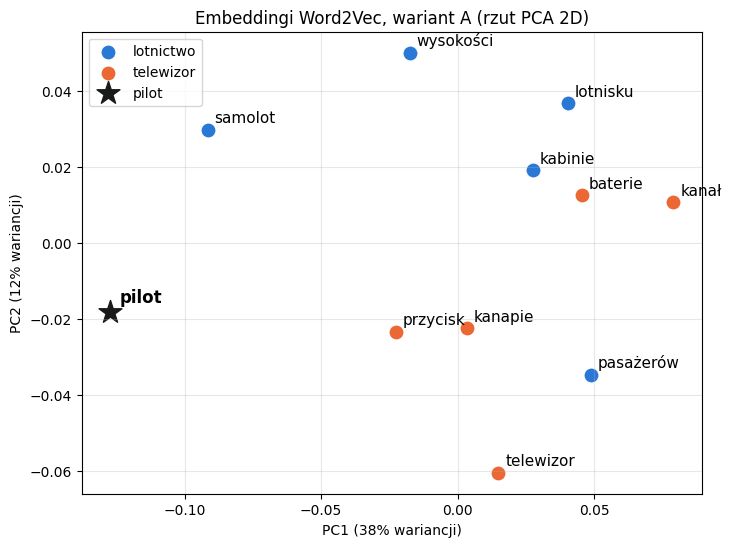

In [11]:
wv = modele['A'].wv
punkty = GRUPA_LOT + GRUPA_TV + [WYRAZ]
pca = PCA(n_components=2, random_state=0)
XY = pca.fit_transform(np.stack([wv[w] for w in punkty]))
wsp = dict(zip(punkty, XY))

plt.figure(figsize=(8, 6))
for grupa, kolor, etykieta in [(GRUPA_LOT, '#2a78d6', 'lotnictwo'),
                               (GRUPA_TV, '#eb6834', 'telewizor')]:
    xy = np.stack([wsp[w] for w in grupa])
    plt.scatter(xy[:, 0], xy[:, 1], s=80, color=kolor, label=etykieta)
    for w in grupa:
        plt.annotate(w, wsp[w], xytext=(5, 5), textcoords='offset points', fontsize=11)
plt.scatter(*wsp[WYRAZ], s=300, marker='*', color='#1a1a1a', label=WYRAZ)
plt.annotate(WYRAZ, wsp[WYRAZ], xytext=(7, 7), textcoords='offset points', fontsize=12,
             fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} wariancji)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} wariancji)')
plt.title('Embeddingi Word2Vec, wariant A (rzut PCA 2D)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 10. Średnie podobieństwo cosinusowe w grupach

In [12]:
zestawy = {
    'wewnątrz grupy lotnictwo': list(combinations(GRUPA_LOT, 2)),
    'wewnątrz grupy telewizor': list(combinations(GRUPA_TV, 2)),
    'między grupami': list(product(GRUPA_LOT, GRUPA_TV)),
}
for nazwa, pary in zestawy.items():
    cos = [wv.similarity(a, b) for a, b in pary]
    print(f'{nazwa:26s} par: {len(pary):2d}   średni cosinus: {np.mean(cos):.3f}')

for nazwa, pary in zestawy.items():
    print(f'\n{nazwa}:')
    for a, b in pary:
        print(f'  {a:10s} {b:10s} {wv.similarity(a, b):.3f}')

wewnątrz grupy lotnictwo   par: 10   średni cosinus: 0.578
wewnątrz grupy telewizor   par: 10   średni cosinus: 0.515
między grupami             par: 25   średni cosinus: 0.528

wewnątrz grupy lotnictwo:
  samolot    lotnisku   0.587
  samolot    kabinie    0.750
  samolot    pasażerów  0.551
  samolot    wysokości  0.772
  lotnisku   kabinie    0.477
  lotnisku   pasażerów  0.323
  lotnisku   wysokości  0.656
  kabinie    pasażerów  0.431
  kabinie    wysokości  0.669
  pasażerów  wysokości  0.563

wewnątrz grupy telewizor:
  telewizor  kanał      0.368
  telewizor  kanapie    0.575
  telewizor  baterie    0.507
  telewizor  przycisk   0.612
  kanał      kanapie    0.381
  kanał      baterie    0.401
  kanał      przycisk   0.464
  kanapie    baterie    0.444
  kanapie    przycisk   0.757
  baterie    przycisk   0.636

między grupami:
  samolot    telewizor  0.647
  samolot    kanał      0.446
  samolot    kanapie    0.722
  samolot    baterie    0.623
  samolot    przycisk   0.750
  